# Preliminary space-charge field

This notebook constructs a modulated entrance beam and visualizes the fixed upstream prefill field `Esz00`. The evolving in-domain fields `Esztotal`, `Esz0`, and `Esz` remain zero here because the notebook only initializes the state and does not call `SpaceChargeState.update()`.

In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

current_directory = Path.cwd().resolve()
possible_project_directories = [
    current_directory,
    current_directory / "pyKlyC",
    current_directory.parent,
]
project_directory = next(
    path for path in possible_project_directories if (path / "src").exists()
)
sys.path.insert(0, str(project_directory / "src"))

from constants import mu0
from model.beam import BeamParameters
from model.cavity import CavityParameters
from model.settings import NumericalSettings
from model.tube import TubeParameters
from solver.beam_state import BeamState
from solver.grid import GridParameters
from solver.reference import ReferenceParameters
from solver.space_charge import SpaceChargeState

## Beam, grid, and space-charge state

The entrance current contains first- and second-harmonic modulation so that the corresponding prefill harmonics can be inspected.

In [3]:
Nc = 1
Ns = 4
Nz = 128
factor = 1.0
factorregion = 10.0
fillfactor = 1.0
DCSPfactor = 1.0

f = 1.0
Nt = 256
t0 = 2.0 * np.pi * np.arange(Nt) / Nt
Ut = np.full(Nt, 180.0)
Izt = -16.0 * (
    1.0
    + 0.35 * np.cos(t0)
    + 0.15 * np.cos(2.0 * t0 - np.pi / 4.0)
)
Y0 = np.arange(Nt)

numerical = NumericalSettings(
    f=f, Nc=Nc, Ns=Ns, Nz=Nz, Nlimit=100, Ntimes=10,
    Rlimit=1.0e-4, iterfactor=0.5,
    evolutionmethod=np.array([0.005, 2.0]),
)
beam = BeamParameters(
    Nbeam=1, rm2=6.0, rm1=0.0, rc=10.0,
    xb=0.0, yb=0.0, xd=0.0, yd=0.0, Nt=Nt,
    t0=t0, Ut=Ut, Izt=Izt, tn1=t0.copy(), Y0=Y0,
)
cavities = CavityParameters(
    type=np.array([1]), nh=np.array([1]), f0=np.array([f]),
    Qext=np.array([1.0]), Qin=np.array([1.0]),
    zshift=np.array([150.0]), Pin=np.array([0.0]),
    gaman=np.zeros(Nc, dtype=complex),
    Lsb=np.pi * np.ones(Nc),
    cavityname="visualization_cavity",
    kai=np.zeros((Nc, Nc), dtype=complex),
)
z0 = 0.0
L = 300.0
tube = TubeParameters(
    z0=z0,
    L=L,
    rcv=np.array([[z0 - beam.rc, z0 + L + beam.rc], [1.0, 1.0]]),
)

reference = ReferenceParameters.calculate_reference_parameters(beam)
grid = GridParameters.calculate(
    numerical, cavities, tube, beam, reference, factorregion
)
beam_state = BeamState.initialize(numerical, beam, grid, reference)
space_charge_state = SpaceChargeState.initialize(
    beam, grid, reference, beam_state, factor, fillfactor, DCSPfactor
)

print(f"wp = {space_charge_state.wp:.6e} rad/s")
print(f"wp / (2 pi) = {space_charge_state.wp / (2.0 * np.pi):.6e} Hz")
print(f"wp / w = {space_charge_state.wp / grid.w:.6e}")
print(f"dN = {grid.dN}")
print(f"Esz00 shape = {space_charge_state.Esz00.shape}")

wp = 3.731666e+09 rad/s
wp / (2 pi) = 5.939130e+08 Hz
wp / w = 5.939130e-01
dN = 26
Esz00 shape = (191, 5)


## Radial space-charge coupling

`Eszr` combines MATLAB's `Eszr1` through `Eszr5`. Its rows follow the normal longitudinal grid and its columns correspond to the first five zeros of $J_0$.

In [ ]:
print(f"SCmethod = {space_charge_state.SCmethod}")
print(f"Eszr shape = {space_charge_state.Eszr.shape}")

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

for mode, root in enumerate(mu0):
    axes[0].plot(
        grid.zi,
        space_charge_state.Eszr[:, mode],
        label=rf"$\mu_{{0,{mode + 1}}}={root:.5f}$",
    )
axes[0].set_ylabel(r"$E_{szr,n}$")
axes[0].set_title("Radial coupling of the five cylindrical modes")
axes[0].grid(alpha=0.25)
axes[0].legend()

Eszr_plot = axes[1].pcolormesh(
    grid.zi,
    np.arange(1, len(mu0) + 1),
    space_charge_state.Eszr.T,
    shading="auto",
)
axes[1].set_xlabel("Global z [mm]")
axes[1].set_ylabel("Cylindrical mode")
axes[1].set_title("Radial-coupling map")
fig.colorbar(Eszr_plot, ax=axes[1], label=r"$E_{szr,n}$")

plt.tight_layout()
plt.show()

## Upstream prefill sources

`zp`, `gamazp`, and `QQfill` are stored in `SpaceChargeState` with the same `(Nfill, Ns + 1)` layout used by MATLAB.

zp shape = (26, 5)
gamazp shape = (26, 5)
QQfill shape = (26, 5)


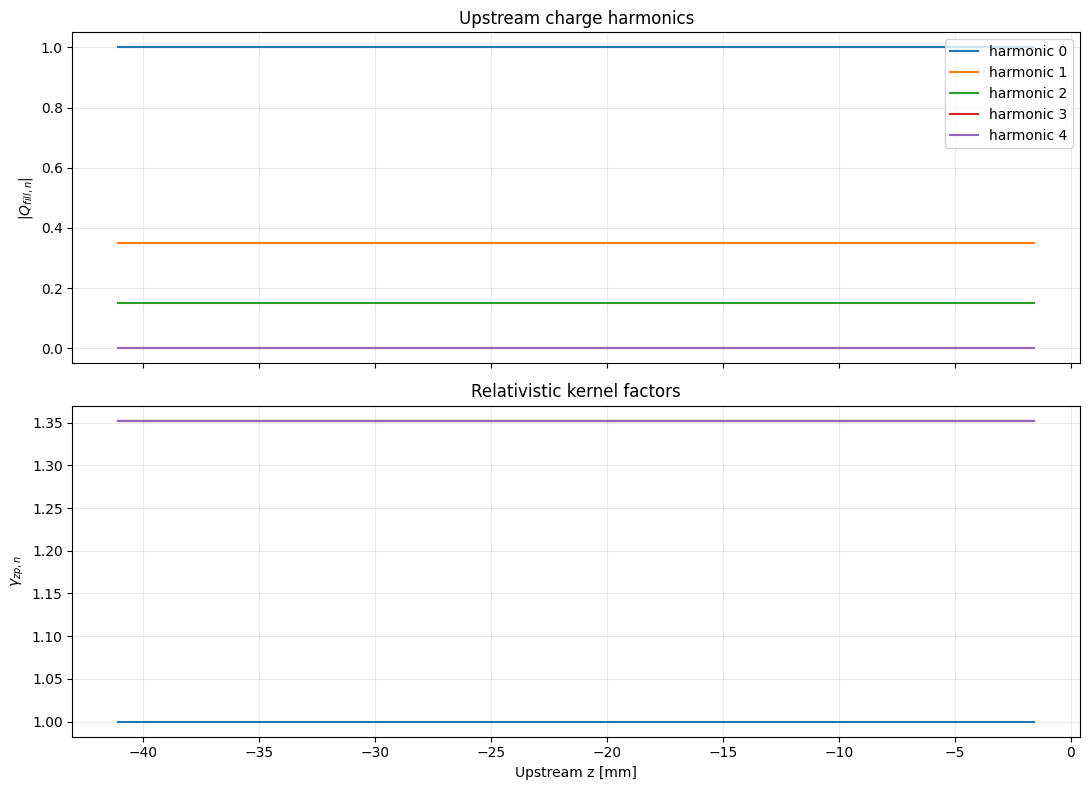

In [4]:
print(f"zp shape = {space_charge_state.zp.shape}")
print(f"gamazp shape = {space_charge_state.gamazp.shape}")
print(f"QQfill shape = {space_charge_state.QQfill.shape}")

zp_mm = space_charge_state.zp[:, 0] / grid.betae
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

for harmonic in range(Ns + 1):
    axes[0].plot(
        zp_mm,
        np.abs(space_charge_state.QQfill[:, harmonic]),
        label=f"harmonic {harmonic}",
    )
axes[0].set_ylabel(r"$|Q_{fill,n}|$")
axes[0].set_title("Upstream charge harmonics")
axes[0].grid(alpha=0.25)
axes[0].legend()

for harmonic in range(Ns + 1):
    axes[1].plot(
        zp_mm,
        space_charge_state.gamazp[:, harmonic],
        label=f"harmonic {harmonic}",
    )
axes[1].set_xlabel("Upstream z [mm]")
axes[1].set_ylabel(r"$\gamma_{zp,n}$")
axes[1].set_title("Relativistic kernel factors")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

## Auxiliary upstream grid and resulting prefill field

The blue solver grid is not enlarged. The orange `zp` points form a separate upstream source grid. `QQfill` is defined on that auxiliary grid and produces `Esz00`, which is evaluated on the normal solver grid.

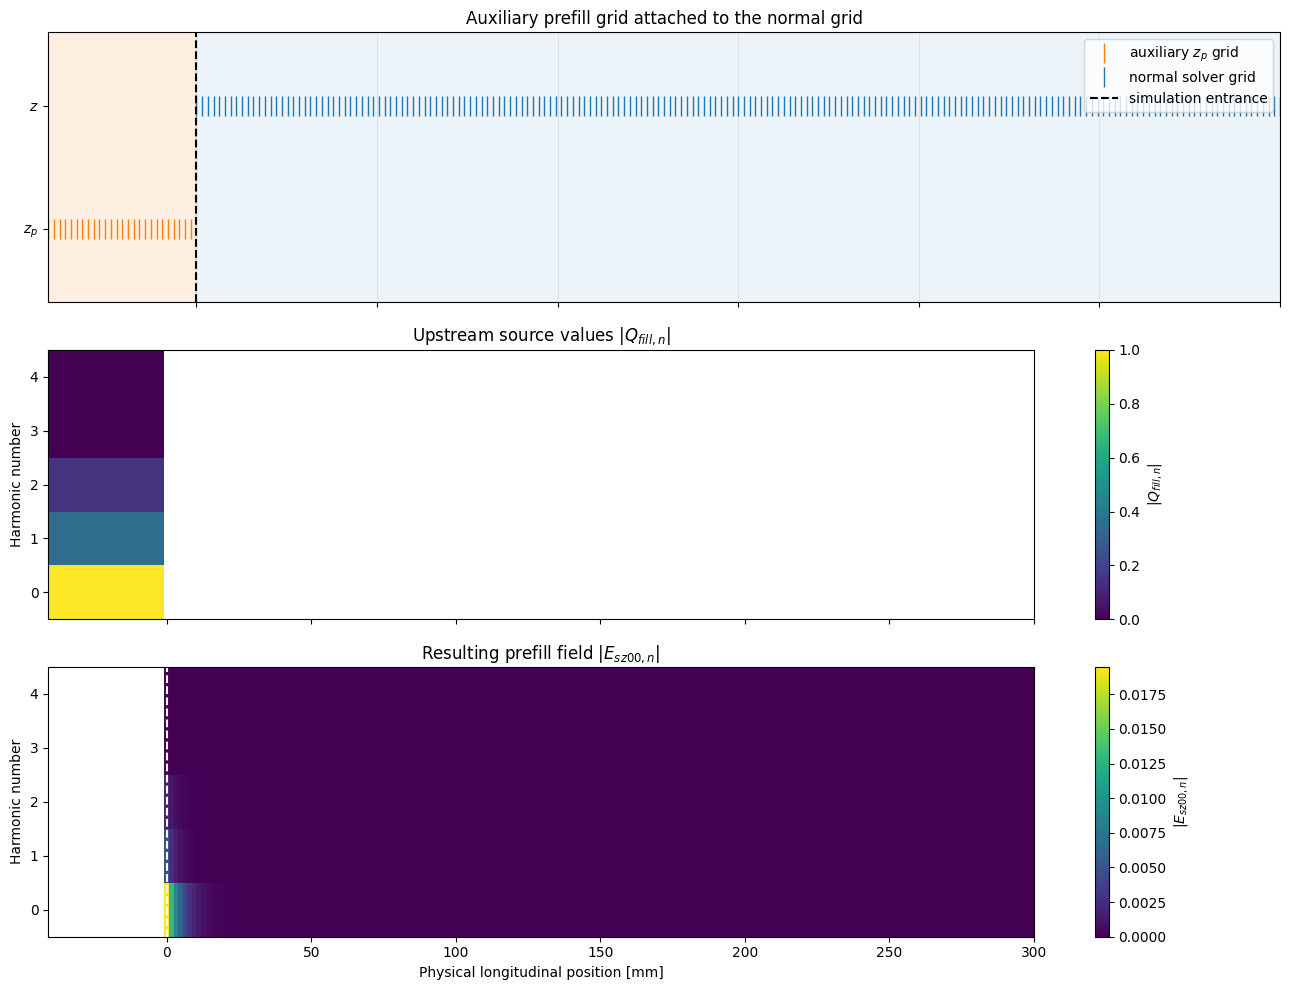

In [5]:
source_order = np.argsort(zp_mm)
zp_mm_sorted = zp_mm[source_order]
Nfill = len(zp_mm_sorted)
harmonic_indices = np.arange(Ns + 1)
extended_z = np.concatenate((zp_mm_sorted, grid.zi))

QQfill_extended = np.full((Ns + 1, len(extended_z)), np.nan)
QQfill_extended[:, :Nfill] = np.abs(
    space_charge_state.QQfill[source_order]
).T

Esz00_extended = np.full((Ns + 1, len(extended_z)), np.nan)
Esz00_extended[:, Nfill:] = np.abs(space_charge_state.Esz00).T

fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)

axes[0].axvspan(
    extended_z[0], grid.zi[0], color="tab:orange", alpha=0.12
)
axes[0].axvspan(
    grid.zi[0], grid.zi[-1], color="tab:blue", alpha=0.08
)
axes[0].plot(
    zp_mm_sorted, np.zeros(Nfill), linestyle="none", marker="|",
    markersize=14, color="tab:orange", label=r"auxiliary $z_p$ grid",
)
axes[0].plot(
    grid.zi, np.ones(len(grid.zi)), linestyle="none", marker="|",
    markersize=14, color="tab:blue", label="normal solver grid",
)
axes[0].axvline(
    grid.zi[0], color="black", linestyle="--", label="simulation entrance"
)
axes[0].set_yticks([0, 1], [r"$z_p$", r"$z$"])
axes[0].set_ylim(-0.6, 1.6)
axes[0].set_title("Auxiliary prefill grid attached to the normal grid")
axes[0].grid(axis="x", alpha=0.25)
axes[0].legend(loc="upper right")

QQfill_plot = axes[1].pcolormesh(
    extended_z, harmonic_indices, QQfill_extended, shading="auto"
)
axes[1].axvline(grid.zi[0], color="white", linestyle="--")
axes[1].set_ylabel("Harmonic number")
axes[1].set_title(r"Upstream source values $|Q_{fill,n}|$")
fig.colorbar(QQfill_plot, ax=axes[1], label=r"$|Q_{fill,n}|$")

Esz00_plot = axes[2].pcolormesh(
    extended_z, harmonic_indices, Esz00_extended, shading="auto"
)
axes[2].axvline(grid.zi[0], color="white", linestyle="--")
axes[2].set_xlabel("Physical longitudinal position [mm]")
axes[2].set_ylabel("Harmonic number")
axes[2].set_title(r"Resulting prefill field $|E_{sz00,n}|$")
fig.colorbar(Esz00_plot, ax=axes[2], label=r"$|E_{sz00,n}|$")

axes[2].set_xlim(extended_z[0], extended_z[-1])
plt.tight_layout()
plt.show()

## Prefill field along the longitudinal grid

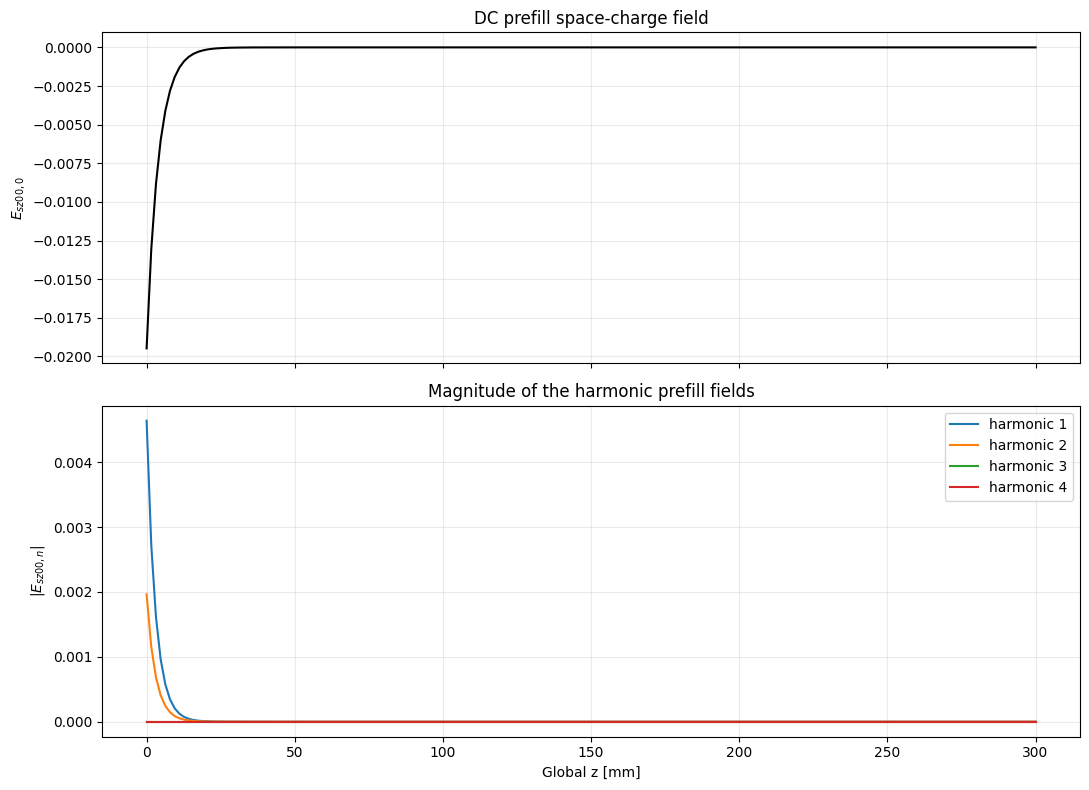

In [6]:
Esz00 = space_charge_state.Esz00
harmonics = np.arange(Ns + 1)

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

axes[0].plot(grid.zi, Esz00[:, 0].real, color="black")
axes[0].set_ylabel(r"$E_{sz00,0}$")
axes[0].set_title("DC prefill space-charge field")
axes[0].grid(alpha=0.25)

for harmonic in range(1, Ns + 1):
    axes[1].plot(
        grid.zi,
        np.abs(Esz00[:, harmonic]),
        label=f"harmonic {harmonic}",
    )
axes[1].set_xlabel("Global z [mm]")
axes[1].set_ylabel(r"$|E_{sz00,n}|$")
axes[1].set_title("Magnitude of the harmonic prefill fields")
axes[1].grid(alpha=0.25)
axes[1].legend()

plt.tight_layout()
plt.show()

## Harmonic magnitude and phase

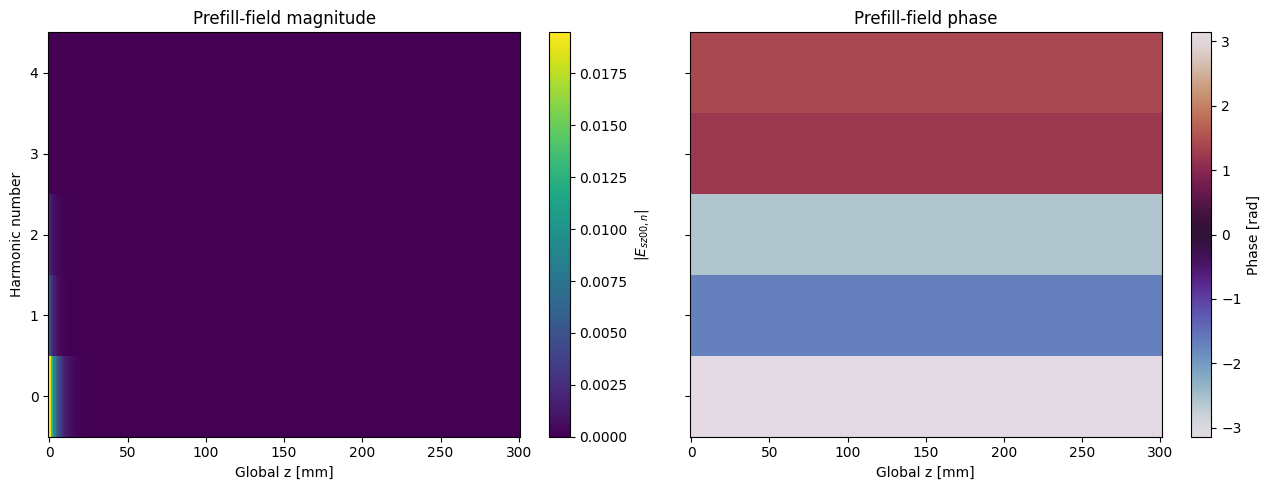

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

magnitude_plot = axes[0].pcolormesh(
    grid.zi, harmonics, np.abs(Esz00).T, shading="auto"
)
axes[0].set_xlabel("Global z [mm]")
axes[0].set_ylabel("Harmonic number")
axes[0].set_title("Prefill-field magnitude")
fig.colorbar(magnitude_plot, ax=axes[0], label=r"$|E_{sz00,n}|$")

phase_plot = axes[1].pcolormesh(
    grid.zi, harmonics, np.angle(Esz00).T, shading="auto",
    cmap="twilight", vmin=-np.pi, vmax=np.pi,
)
axes[1].set_xlabel("Global z [mm]")
axes[1].set_title("Prefill-field phase")
fig.colorbar(phase_plot, ax=axes[1], label="Phase [rad]")

plt.tight_layout()
plt.show()

## Reconstructed field over one RF period

The MATLAB field convention is $E(\theta)=E_0+\sum_n\operatorname{Im}(E_n e^{in\theta})$.

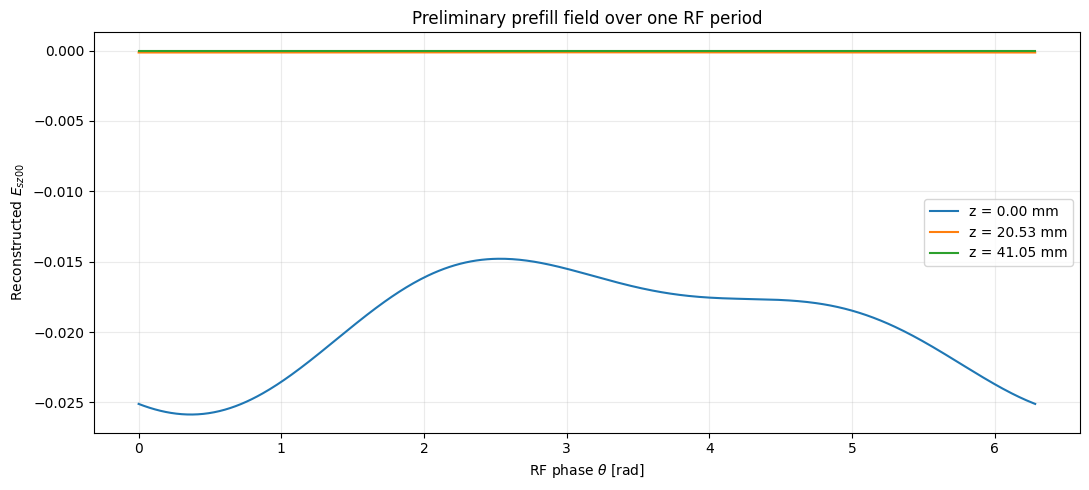

In [8]:
theta = np.linspace(0.0, 2.0 * np.pi, 500)
harmonic_numbers = np.arange(1, Ns + 1)[:, np.newaxis]
z_indices = [
    0,
    min(grid.dN // 2, len(grid.zi) - 1),
    min(grid.dN, len(grid.zi) - 1),
]

fig, ax = plt.subplots(figsize=(11, 5))
for index in z_indices:
    reconstructed_field = Esz00[index, 0].real + np.sum(
        np.imag(
            Esz00[index, 1:, np.newaxis]
            * np.exp(1.0j * harmonic_numbers * theta)
        ),
        axis=0,
    )
    ax.plot(
        theta, reconstructed_field, label=f"z = {grid.zi[index]:.2f} mm"
    )

ax.set_xlabel(r"RF phase $\theta$ [rad]")
ax.set_ylabel(r"Reconstructed $E_{sz00}$")
ax.set_title("Preliminary prefill field over one RF period")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()